# KNN Predicting Obesity Level

goal: predict `obesity_level` from lifestyle habits

### required imports

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

#### Preprocess data

In [12]:
data = Path("../data/clean_data/cleaned_obesity_data.csv")
df = pd.read_csv(data)
df = df.drop_duplicates()
df.shape

(2087, 17)

#### Choosing features 'X' and target 'y'

We are dropping the height and weight here because it would over simplify the prediction problem. This is due to the fact that BMI = (weight / height^2)

In [13]:
X = df.drop(columns = ["obesity_level", "Height", "Weight"])
y = df["obesity_level"]

In [14]:
X = pd.get_dummies(X, columns=["Gender", "CAEC", "CALC", "MTRANS"], drop_first = True, dtype= int)
X.head()

,Age,family_history_with_overweight,FAVC,FCVC,NCP,SMOKE,CH2O,SCC,FAF,TUE,...,CAEC_Frequently,CAEC_Sometimes,CAEC_no,CALC_Frequently,CALC_Sometimes,CALC_no,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,21.0,1,0,2.0,3.0,0,2.0,0,0.0,1.0,...,0,1,0,0,0,1,0,0,1,0
1,21.0,1,0,3.0,3.0,1,3.0,1,3.0,0.0,...,0,1,0,0,1,0,0,0,1,0
2,23.0,1,0,2.0,3.0,0,2.0,0,2.0,1.0,...,0,1,0,1,0,0,0,0,1,0
3,27.0,0,0,3.0,3.0,0,2.0,0,2.0,0.0,...,0,1,0,1,0,0,0,0,0,1
4,22.0,0,0,2.0,1.0,0,2.0,0,0.0,0.0,...,0,1,0,0,1,0,0,0,1,0


#### Train / test split

Same split as the random forest notebook (`random_state=42`, stratified) so both models are scored on the same test set.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1669, 21) Test: (418, 21)


#### Build the pipeline

KNN classifies by distance, so features with larger ranges dominate (Age runs 14-61, the dummy columns are 0/1).
`StandardScaler` puts every feature on the same scale.

In [16]:
pipe = Pipeline([
    ("scaler", StandardScaler()), #it is super essential to scale the features here
    ("knn", KNeighborsClassifier()),
])

#### Tune hyperparameters with GridSearchCV

The search space is small thus we can try every combination:
- `n_neighbors`: odd k from 1 to 29 (odd avoids ties)
- `weights`: `uniform` (every neighbor gets one vote) or `distance` (closer neighbors count more)
- `p`: 1 = Manhattan distance, 2 = Euclidean distance

In [18]:
param_grid = {
    "knn__n_neighbors": list(range(1, 31, 2)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

search = GridSearchCV(
    pipe, 
    param_grid, 
    cv=10, 
    scoring="f1_macro", 
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Best CV macro F1: %.3f" % search.best_score_)

Best settings: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV macro F1: 0.796


#### Choosing k

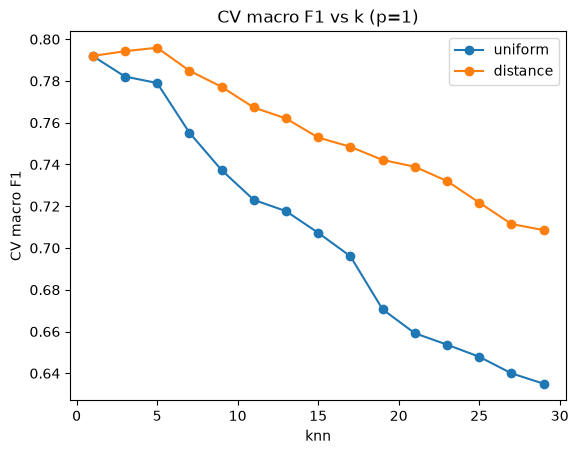

In [19]:
res = pd.DataFrame(search.cv_results_)
best_p = search.best_params_["knn__p"]

for w in ["uniform", "distance"]:
    sub = res[(res["param_knn__weights"] == w) & (res["param_knn__p"] == best_p)]

    plt.plot(sub["param_knn__n_neighbors"], sub["mean_test_score"], marker="o", label=w)

plt.xlabel("knn")
plt.ylabel("CV macro F1")
plt.title("CV macro F1 vs k (p=%d)" % best_p)
plt.legend()
plt.show()

#### Test the best model on the test set

In [20]:
best_knn = search.best_estimator_
y_pred = best_knn.predict(X_test)

print("Test acc: %.4f" % accuracy_score(y_test, y_pred) + f"\n")
print(classification_report(y_test, y_pred))

Test acc: 0.7679

                     precision    recall  f1-score   support

Insufficient_Weight       0.83      0.92      0.88        53
      Normal_Weight       0.52      0.47      0.50        57
     Obesity_Type_I       0.78      0.81      0.80        70
    Obesity_Type_II       0.82      0.88      0.85        60
   Obesity_Type_III       0.93      0.98      0.96        65
 Overweight_Level_I       0.68      0.65      0.67        55
Overweight_Level_II       0.74      0.60      0.67        58

           accuracy                           0.77       418
          macro avg       0.76      0.76      0.76       418
       weighted avg       0.76      0.77      0.76       418



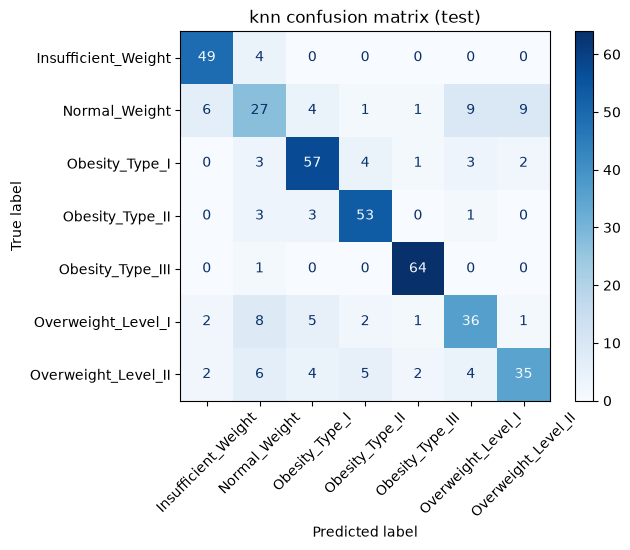

In [21]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=best_knn.classes_).plot(xticks_rotation=45, cmap="Blues")

plt.title("knn confusion matrix (test)")
plt.show()

#### Scaled vs unscaled

Same grid search without the scaler to show see how much scaling actually changes the result.

In [22]:
unscaled = GridSearchCV(Pipeline([("knn", KNeighborsClassifier())]), param_grid, cv=10, scoring="f1_macro", n_jobs=-1)
unscaled.fit(X_train, y_train)

comparison = pd.DataFrame({
    "best settings": [search.best_params_, unscaled.best_params_],
    "CV macro F1": [search.best_score_, unscaled.best_score_],
    "test accuracy": [accuracy_score(y_test, search.predict(X_test)), accuracy_score(y_test, unscaled.predict(X_test))],
    "test macro F1": [f1_score(y_test, search.predict(X_test), average="macro"), f1_score(y_test, unscaled.predict(X_test), average="macro")],
}, index=["scaled", "unscaled"])

comparison.round(3)

,best settings,CV macro F1,test accuracy,test macro F1
scaled,"{'knn__n_neighbors': 5, 'knn__p': 1, 'knn__wei...",0.796,0.768,0.758
unscaled,"{'knn__n_neighbors': 1, 'knn__p': 1, 'knn__wei...",0.807,0.813,0.802


#### Notes

- K was found best when it was a small value. Due to some of the data being synthetically generated via SMOTE it best works with small cluster sizes.

- Scaling is the principled choice for KNN, but in this data the unscaled model can do as well or better, likely because Age is a strong signal and unscaled distance is dominated by Age.